### 1. Imports


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

### 2.1 Objective and Problem Definition

Στόχος μας είναι να εντοπίσουμε ομάδες κατοικιών με παρόμοια φυσικά
και δομικά χαρακτηριστικά. Εξετάζουμε αν τα σπίτια μπορούν να χωριστούν
σε ομάδες με βάση το μέγεθος του οικοπέδου, του κατοικήσιμου χώρου,
του υπογείου και του garage.

Φορτώνουμε το επεξεργασμένο training dataset που αποθηκεύσαμε στο
preprocessing και βλέπουμε τις διαστάσεις και τις πρώτες γραμμές του.
Τα numerical χαρακτηριστικά έχουν ήδη γίνει scale με `StandardScaler`.
Το `SalePrice` υπάρχει στο αρχείο, αλλά δεν θα το χρησιμοποιήσουμε
για να σχηματίσουμε τις ομάδες.

In [2]:
train = pd.read_csv("../data/processed/train_processed.csv")

print(train.shape)
train.head()

(1460, 362)


,Id,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,BsmtFinSF2,...,SaleType_Oth,SaleType_Unknown,SaleType_WD,SaleCondition_Abnorml,SaleCondition_AdjLand,SaleCondition_Alloca,SaleCondition_Family,SaleCondition_Normal,SaleCondition_Partial,SaleCondition_Unknown
0,1,-0.231877,-0.207142,0.651479,-0.517200,1.050994,0.878668,0.507985,0.575425,-0.288653,...,False,False,True,False,False,False,False,True,False,False
1,2,0.437043,-0.091886,-0.071836,2.179628,0.156734,-0.429577,-0.576950,1.171992,-0.288653,...,False,False,True,False,False,False,False,True,False,False
2,3,-0.098093,0.073480,0.651479,-0.517200,0.984752,0.830215,0.319782,0.092907,-0.288653,...,False,False,True,False,False,False,False,True,False,False
3,4,-0.454850,-0.096897,0.651479,-0.517200,-1.863632,-0.720298,-0.576950,-0.499274,-0.288653,...,False,False,True,True,False,False,False,False,False,False
4,5,0.615421,0.375148,1.374795,-0.517200,0.951632,0.733308,1.360433,0.463568,-0.288653,...,False,False,True,False,False,False,False,True,False,False


### 2.2 Feature Selection

Κρατάμε τέσσερα χαρακτηριστικά που περιγράφουν διαφορετικές πλευρές
του μεγέθους μιας κατοικίας:

- `GrLivArea`: επιφάνεια κατοικήσιμου χώρου πάνω από το έδαφος.
- `GarageArea`: επιφάνεια garage.
- `TotalBsmtSF`: συνολική επιφάνεια υπογείου.
- `LotArea`: συνολική επιφάνεια οικοπέδου.

Δημιουργούμε το `X` με αντίγραφο αυτών των στηλών. Έτσι, τα μοντέλα
θα χρησιμοποιήσουν μόνο αυτά τα χαρακτηριστικά και όχι το `SalePrice`.
Χρησιμοποιούμε την ευκλείδεια απόσταση, η οποία είναι και η προεπιλογή
του DBSCAN. Το scaling που έχει προηγηθεί βοηθά ώστε οι διαφορετικές
κλίμακες των αρχικών μετρήσεων να μην καθορίζουν από μόνες τους τις αποστάσεις.

In [3]:
clustering_features = [
    "GrLivArea",
    "GarageArea",
    "TotalBsmtSF",
    "LotArea"
]

X = train[clustering_features].copy()

X.head()

,GrLivArea,GarageArea,TotalBsmtSF,LotArea
0,0.370333,0.351000,-0.459303,-0.207142
1,-0.482512,-0.060731,0.466465,-0.091886
2,0.515013,0.631726,-0.313369,0.073480
3,0.383659,0.790804,-0.687324,-0.096897
4,1.299326,1.698485,0.199680,0.375148


### 2.3 Visual Exploration of Selected Features

Πριν εφαρμόσουμε τους αλγορίθμους, εξετάζουμε τη σχέση μεταξύ των
χαρακτηριστικών με scatter plots. Κάθε σημείο αντιστοιχεί σε μία κατοικία.

Στο πρώτο γράφημα συγκρίνουμε το `GrLivArea` με το `LotArea`, για να
δούμε πώς συνδέεται ο κατοικήσιμος χώρος με το μέγεθος του οικοπέδου
και αν υπάρχουν σημεία που ξεχωρίζουν από τα υπόλοιπα.
Οι άξονες δείχνουν τις τιμές μετά το scaling και όχι τις αρχικές επιφάνειες.

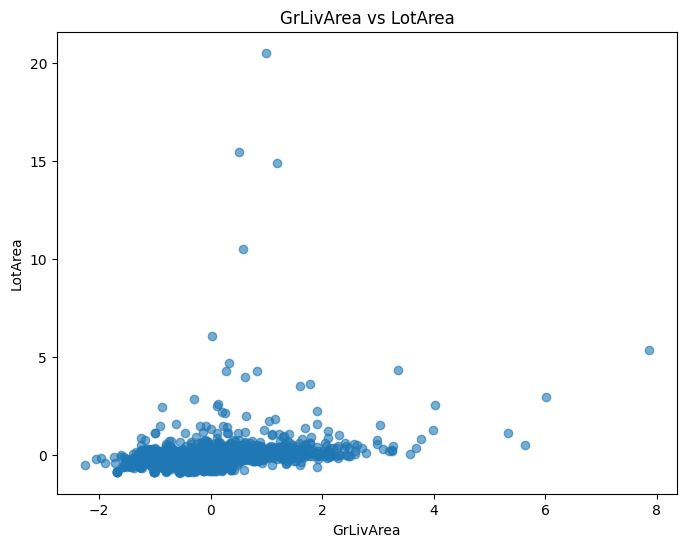

In [4]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X["GrLivArea"],
    X["LotArea"],
    alpha=0.6
)

plt.xlabel("GrLivArea")
plt.ylabel("LotArea")
plt.title("GrLivArea vs LotArea")

plt.show()

Στο δεύτερο scatter plot συγκρίνουμε το `GarageArea` με το
`TotalBsmtSF`. Εξετάζουμε αν μεγαλύτερα garage συνδέονται με μεγαλύτερα
υπόγεια και αν υπάρχουν κατοικίες που ξεχωρίζουν από τις υπόλοιπες.
Και εδώ χρησιμοποιούμε τις τιμές μετά το scaling.

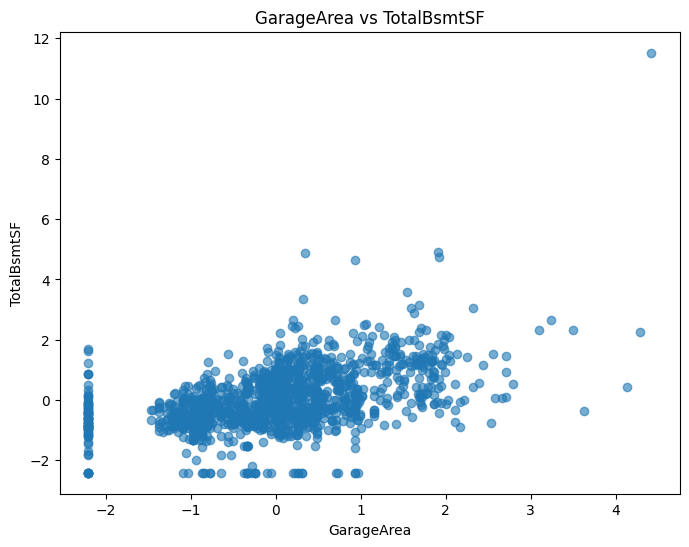

In [5]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X["GarageArea"],
    X["TotalBsmtSF"],
    alpha=0.6
)

plt.xlabel("GarageArea")
plt.ylabel("TotalBsmtSF")
plt.title("GarageArea vs TotalBsmtSF")

plt.show()

### 2.4 K-Means Clustering

Δοκιμάζουμε τον K-Means για διαφορετικό αριθμό clusters, από `k = 2`
έως `k = 6`. Για κάθε δοκιμή υπολογίζουμε το Silhouette Score και το
αποθηκεύουμε στη λίστα `silhouette_scores`.

Μεγαλύτερη τιμή του score δείχνει πιο καθαρό διαχωρισμό των ομάδων
με βάση την απόσταση που χρησιμοποιούμε. Το `random_state = 42`
βοηθά στην αναπαραγωγή της δοκιμής, ενώ με `n_init = 10` ο αλγόριθμος
δοκιμάζει δέκα διαφορετικές αρχικοποιήσεις των κέντρων.

In [6]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    labels = kmeans.fit_predict(X)
    
    score = silhouette_score(X, labels)
    
    silhouette_scores.append(score)

silhouette_scores

[0.3572064381385183,
 0.3516209233337573,
 0.24924498126677927,
 0.26252590392711606,
 0.23848145536368348]

### 2.5 Selection of the Number of Clusters

Παρουσιάζουμε σε γράφημα το Silhouette Score για κάθε τιμή του `k`,
ώστε να συγκρίνουμε πιο εύκολα τις δοκιμές μας.

Στα αποθηκευμένα αποτελέσματα, το υψηλότερο score είναι περίπου
`0.3572` για `k = 2`. Με βάση αυτό το κριτήριο, επιλέγουμε δύο clusters
για το τελικό μοντέλο K-Means, ανάμεσα στις τιμές που δοκιμάσαμε.

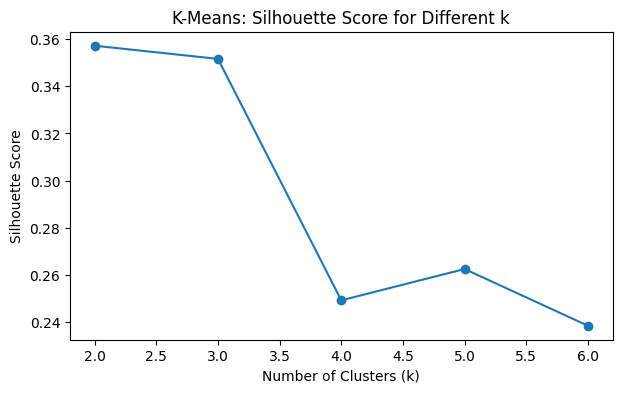

In [7]:
plt.figure(figsize=(7, 4))

plt.plot(
    range(2, 7),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("K-Means: Silhouette Score for Different k")

plt.show()

### 2.6 Final K-Means Clustering

Εφαρμόζουμε ξανά τον K-Means με `k = 2`, όπως επιλέξαμε από την
προηγούμενη σύγκριση. Με το `fit_predict` παίρνουμε την ετικέτα
του cluster για κάθε κατοικία και την κρατάμε στο `kmeans_labels`.

Υπολογίζουμε επίσης το Silhouette Score του τελικού μοντέλου,
ώστε να το χρησιμοποιήσουμε στη σύγκριση με τον DBSCAN.

In [8]:
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans.fit_predict(X)

silhouette_kmeans = silhouette_score(
    X,
    kmeans_labels
)

print("K-Means Silhouette Score:", silhouette_kmeans)

K-Means Silhouette Score: 0.3572064381385183


Μετράμε πόσες κατοικίες ανήκουν σε κάθε cluster του K-Means.
Έτσι βλέπουμε αν οι δύο ομάδες έχουν παρόμοιο μέγεθος ή αν η μία
περιλαμβάνει πολύ περισσότερες κατοικίες. Οι αριθμοί των ετικετών
ξεχωρίζουν απλώς τις ομάδες και δεν δηλώνουν κάποια κατάταξη.

In [9]:
pd.Series(kmeans_labels).value_counts()

1    994
0    466
Name: count, dtype: int64

### 2.7 Visualisation of K-Means Clusters

Σχεδιάζουμε ξανά το `GrLivArea` σε σχέση με το `LotArea`, αυτή τη φορά
χρωματίζοντας κάθε κατοικία ανάλογα με το cluster της.

Έτσι βλέπουμε πώς εμφανίζονται οι ομάδες σε αυτά τα δύο χαρακτηριστικά.
Ο διαχωρισμός του μοντέλου έχει γίνει και με τα τέσσερα χαρακτηριστικά
του `X`, οπότε το γράφημα δείχνει μόνο ένα μέρος της συνολικής εικόνας.

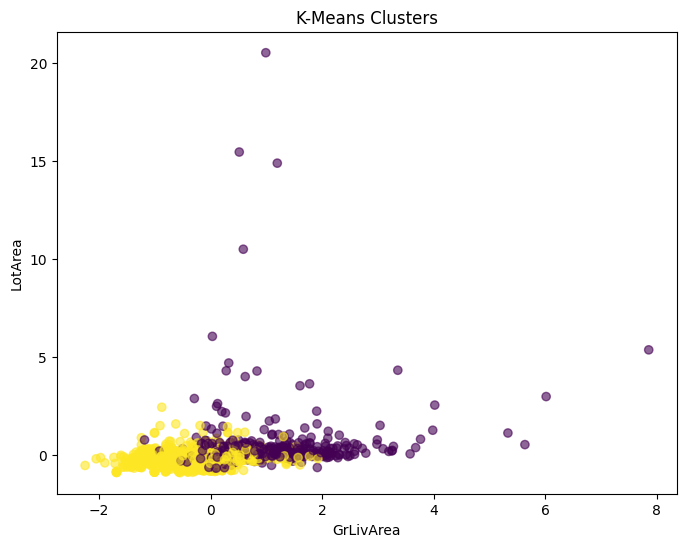

In [10]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X["GrLivArea"],
    X["LotArea"],
    c=kmeans_labels,
    alpha=0.6
)

plt.xlabel("GrLivArea")
plt.ylabel("LotArea")
plt.title("K-Means Clusters")

plt.show()

### 2.8 DBSCAN Clustering

Εφαρμόζουμε τον DBSCAN στα ίδια δεδομένα, αρχικά με `eps = 0.5`
και `min_samples = 5`. Το `eps` ορίζει την ακτίνα της γειτονιάς γύρω
από κάθε σημείο, ενώ το `min_samples` ορίζει πόσα σημεία χρειάζονται
μέσα σε αυτή, μαζί με το ίδιο το σημείο, για να θεωρηθεί πυρήνας μιας ομάδας.

Ο DBSCAN σχηματίζει ομάδες με βάση την πυκνότητα των σημείων,
χωρίς να ορίσουμε από πριν πόσα clusters θέλουμε. Μετράμε πόσες
κατοικίες πήραν κάθε ετικέτα. Η ετικέτα `-1` αντιστοιχεί σε noise,
δηλαδή σε σημεία που δεν εντάχθηκαν σε κάποιο cluster.

In [11]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.5,
    min_samples=5
)

dbscan_labels = dbscan.fit_predict(X)

pd.Series(dbscan_labels).value_counts()

 0    1200
-1     175
 2      58
 3      16
 1       6
 4       5
Name: count, dtype: int64

Υπολογίζουμε το Silhouette Score για την αρχική δοκιμή του DBSCAN.
Με τη μάσκα `mask` κρατάμε μόνο τα σημεία που δεν έχουν ετικέτα `-1`,
ώστε το noise να μη θεωρηθεί μία επιπλέον ομάδα.

Το score περιγράφει επομένως μόνο τις κατοικίες που εντάχθηκαν σε
clusters. Για να υπολογιστεί, χρειάζονται τουλάχιστον δύο clusters
και λιγότερα clusters από τα σημεία που κρατήσαμε.

In [12]:
from sklearn.metrics import silhouette_score

mask = dbscan_labels != -1 # Κραταμε μονο τα σημεια που δεν ειναι noise

X_dbscan = X[mask]
labels_dbscan = dbscan_labels[mask]

silhouette_dbscan = silhouette_score(
    X_dbscan,
    labels_dbscan
)

print("DBSCAN Silhouette Score:", silhouette_dbscan)

DBSCAN Silhouette Score: 0.03634175106799022


Δοκιμάζουμε τις τιμές `0.3`, `0.5`, `0.7` και `1.0` για το `eps`,
κρατώντας σταθερό το `min_samples = 5`. Για κάθε δοκιμή αποθηκεύουμε
το `eps`, το `min_samples`, το Silhouette Score και το πλήθος των noise points.

Ελέγχουμε αν έχουν προκύψει τουλάχιστον δύο clusters μετά την αφαίρεση
του noise. Αν όχι, ο κώδικας αποθηκεύει `-1` ως ένδειξη ότι δεν έγινε
υπολογισμός του score. Αυτή η τιμή δεν είναι μετρημένο αποτέλεσμα
και δεν τη χρησιμοποιούμε για να επιλέξουμε την καλύτερη ρύθμιση.

In [13]:
dbscan_results = []

for eps in [0.3, 0.5, 0.7, 1.0]:
    
    dbscan = DBSCAN(
        eps=eps,
        min_samples=5
    )
    
    labels = dbscan.fit_predict(X)
    
    mask = labels != -1 # Αφαιρουμε τα noise points (-1)
    
    if len(set(labels[mask])) > 1:
        score = silhouette_score(X[mask], labels[mask])
    else:
        score = -1
    
    dbscan_results.append([eps, 5, score, sum(labels == -1)])

dbscan_results

[[0.3, 5, -0.12424395864335662, np.int64(516)],
 [0.5, 5, 0.03634175106799022, np.int64(175)],
 [0.7, 5, 0.229127036680439, np.int64(89)],
 [1.0, 5, -1, np.int64(39)]]

### 2.9 Επίδραση των παραμέτρων του DBSCAN

Από τις προηγούμενες δοκιμές με σταθερό `min_samples = 5`, η τιμή
`eps = 0.7` έδωσε το υψηλότερο έγκυρο Silhouette Score, περίπου
`0.2291`, με 89 noise points.

Στη συνέχεια κρατάμε το `eps = 0.7` και δοκιμάζουμε τιμές του
`min_samples` από τη λίστα `[3, 5, 10, 15]`. Αποθηκεύουμε το score
και το πλήθος των noise points για κάθε δοκιμή.
Έτσι εξετάζουμε πώς αλλάζει το αποτέλεσμα όταν απαιτούμε περισσότερα
γειτονικά σημεία για να σχηματιστεί ο πυρήνας μιας ομάδας.
Και εδώ, το `-1` στη στήλη του score χρησιμοποιείται ως ένδειξη
ότι δεν προέκυψαν τουλάχιστον δύο clusters για τον υπολογισμό του.

In [14]:
dbscan_results_min_samples = []

for min_samples in [3, 5, 10, 15]:
    
    dbscan = DBSCAN( # Δοκιμαζουμε διαφορετικες τιμες του min_samples με σταθερο eps
        eps=0.7,
        min_samples=min_samples
    )
    
    labels = dbscan.fit_predict(X)  # Εφαρμοζουμε τον DBSCAN και παιρνουμε την ετικετα καθε κατοικιας
    
    mask = labels != -1
    
    if len(set(labels[mask])) > 1:  # Υπολογιζουμε το score αν υπαρχουν τουλαχιστον δυο clusters
        score = silhouette_score(X[mask], labels[mask])
    else:
        score = -1 #δεν υπολογιστηκε
    
    dbscan_results_min_samples.append([
        min_samples,
        score,
        sum(labels == -1)
    ])

dbscan_results_min_samples

[[3, 0.11658759317638474, np.int64(71)],
 [5, 0.229127036680439, np.int64(89)],
 [10, 0.2673649814863188, np.int64(117)],
 [15, 0.2722684302466863, np.int64(140)]]

### 2.10 Selection of the Final DBSCAN Parameters

Για `eps = 0.7`, το υψηλότερο Silhouette Score στις δοκιμές μας
προέκυψε με `min_samples = 15`. Επιλέγουμε αυτόν τον συνδυασμό
και εφαρμόζουμε το τελικό μοντέλο.

Κρατάμε τις ετικέτες στο `dbscan_final_labels` και υπολογίζουμε
το score μόνο για τις κατοικίες που δεν χαρακτηρίστηκαν ως noise.
Εμφανίζουμε επίσης το πλήθος των noise points και των clusters.

Στα αποθηκευμένα αποτελέσματα προκύπτουν τρία clusters, 140 noise
points και score περίπου `0.2723`. Το μεγαλύτερο score συνοδεύεται
εδώ από περισσότερα noise points σε σχέση με το `min_samples = 5`,
οπότε λαμβάνουμε υπόψη και πόσες κατοικίες μένουν εκτός των ομάδων.

In [15]:
dbscan_final = DBSCAN(
    eps=0.7,
    min_samples=15
)

dbscan_final_labels = dbscan_final.fit_predict(X)

mask = dbscan_final_labels != -1

silhouette_dbscan_final = silhouette_score(
    X[mask],
    dbscan_final_labels[mask]
)

print("Final DBSCAN Silhouette Score:", silhouette_dbscan_final)
print("Noise points:", sum(dbscan_final_labels == -1))
print("Number of clusters:", len(set(dbscan_final_labels)) - 1)

Final DBSCAN Silhouette Score: 0.2722684302466863
Noise points: 140
Number of clusters: 3


### 2.11 Comparison of K-Means and DBSCAN

Συγκρίνουμε τα Silhouette Scores των τελικών μοντέλων με ένα
ραβδόγραμμα. Ο K-Means έχει score περίπου `0.3572`, ενώ ο DBSCAN
περίπου `0.2723` στα αποθηκευμένα αποτελέσματα.

Ο K-Means εμφανίζει υψηλότερο score, αλλά η σύγκριση χρειάζεται
προσοχή: για τον K-Means υπολογίζεται σε όλες τις κατοικίες,
ενώ για τον DBSCAN έχουν εξαιρεθεί τα noise points.
Επομένως, οι δύο τιμές δίνουν μια χρήσιμη ένδειξη, αλλά δεν αρκούν
από μόνες τους για να κρίνουμε συνολικά ποιος αλγόριθμος είναι καλύτερος.

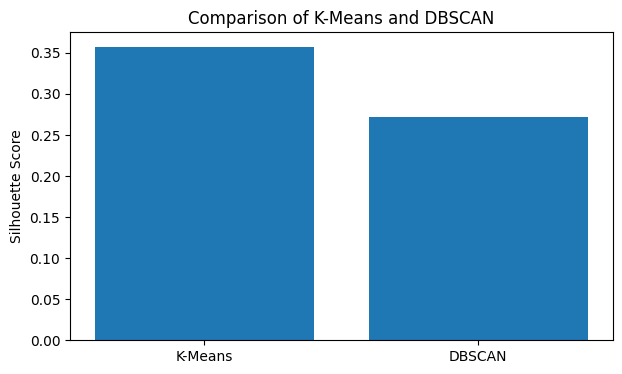

In [16]:
models = ["K-Means", "DBSCAN"]
scores = [silhouette_kmeans, silhouette_dbscan_final]

plt.figure(figsize=(7, 4))

plt.bar(models, scores)

plt.ylabel("Silhouette Score")
plt.title("Comparison of K-Means and DBSCAN")

plt.show()

### 2.12 Visualisation of the Final DBSCAN Clusters

Παρουσιάζουμε τις ομάδες του τελικού DBSCAN με βάση το `GrLivArea`
και το `LotArea`. Το χρώμα κάθε σημείου καθορίζεται από την ετικέτα
που έδωσε το μοντέλο.

Η ετικέτα `-1` δηλώνει noise και δεν αποτελεί κανονικό cluster.
Όπως και στο γράφημα του K-Means, βλέπουμε δύο από τα τέσσερα
χαρακτηριστικά που χρησιμοποιήθηκαν για τη συσταδοποίηση.

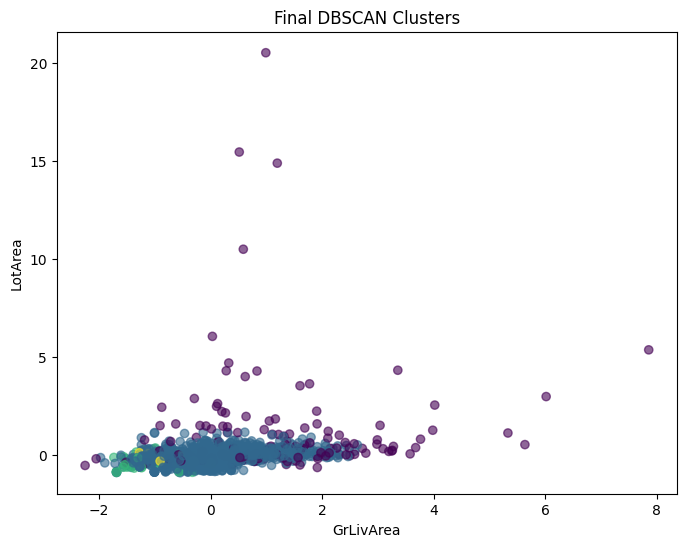

In [17]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X["GrLivArea"],
    X["LotArea"],
    c=dbscan_final_labels,
    alpha=0.6
)

plt.xlabel("GrLivArea")
plt.ylabel("LotArea")
plt.title("Final DBSCAN Clusters")

plt.show()

### 2.13 Execution Time Comparison

Μετράμε τον χρόνο που χρειάζεται κάθε τελικό μοντέλο για να
εκπαιδευτεί στα ίδια δεδομένα. Καταγράφουμε τον χρόνο πριν και
μετά το `fit` και κρατάμε τη διαφορά σε δευτερόλεπτα.

Η μέτρηση αφορά τις συγκεκριμένες ρυθμίσεις των τελικών μοντέλων,
χωρίς τις προηγούμενες δοκιμές παραμέτρων ή τον υπολογισμό του score.
Οι χρόνοι είναι ενδεικτικοί, καθώς μπορεί να αλλάξουν ανάλογα με
τον υπολογιστή και από εκτέλεση σε εκτέλεση.

In [18]:
import time

start = time.time()

kmeans_time_model = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_time_model.fit(X)
kmeans_time = time.time() - start
start = time.time()
dbscan_time_model = DBSCAN(
    eps=0.7,
    min_samples=15
)

dbscan_time_model.fit(X)
dbscan_time = time.time() - start

print("K-Means execution time:", kmeans_time)
print("DBSCAN execution time:", dbscan_time)

K-Means execution time: 0.08093810081481934
DBSCAN execution time: 0.032770633697509766


### 2.14 Conclusions

Χρησιμοποιήσαμε τα `GrLivArea`, `GarageArea`, `TotalBsmtSF` και
`LotArea` για να αναζητήσουμε ομάδες κατοικιών με παρόμοια μεγέθη.
Εφαρμόσαμε K-Means και DBSCAN και δοκιμάσαμε διαφορετικές παραμέτρους.

Για τον K-Means επιλέξαμε `k = 2`, με Silhouette Score περίπου
`0.3572`. Για τον DBSCAN επιλέξαμε `eps = 0.7` και `min_samples = 15`,
με score περίπου `0.2723`, τρία clusters και 140 noise points,
σύμφωνα με τα αποθηκευμένα αποτελέσματα.

Ο K-Means έδωσε υψηλότερο score και εντάσσει κάθε κατοικία σε μια
ομάδα. Ο DBSCAN επιτρέπει να μείνουν εκτός ομάδων κατοικίες που
χαρακτηρίζονται ως noise. Αυτό μπορεί να βοηθήσει στην περαιτέρω
εξέτασή τους, χωρίς να σημαίνει απαραίτητα ότι είναι λανθασμένες τιμές.

Η επιλογή των παραμέτρων επηρεάζει τόσο τον διαχωρισμό όσο και το
πλήθος των σημείων που συμμετέχουν στις ομάδες. Για αυτό συνεκτιμούμε
τα scores, τα γραφήματα, τα noise points και τον χρόνο εκτέλεσης.
Ειδικά στη σύγκριση των scores, θυμόμαστε ότι στον DBSCAN εξαιρέσαμε
το noise, ενώ στον K-Means χρησιμοποιήσαμε όλες τις κατοικίες.